# Laboratorio 9. Series de tiempo y forecasting

## Notebook 1. Datos, exploración y preparación de la serie

En este notebook se arman las primeras etapas del pipeline. Primero se pasa de los datos crudos a series horarias limpias, luego a ventanas y al final a tensores de PyTorch. El código que se reutiliza en los demás notebooks está en la carpeta `src` y aquí solo se llama.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
# pandas 2.3.3 con numpy 2.5 avisa al sumar Timedelta a Timestamp, es un aviso interno de pandas
warnings.filterwarnings("ignore", message="The 'generic' unit for NumPy timedelta")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import torch
from torch.utils.data import DataLoader

from src import config as C
from src import data as D
from src import features as F
from src.dataset import (Escalador, VentanasDataset, contar_ventanas, indice,
                         panel_a_matriz, t0_bloque)
from src.graficas import (AZUL, NARANJA, GRIS, GRIS_CLARO, VERDE, estilo, guardar, pie)

pd.set_option("display.width", 140)

### 1. Datos

Se trabaja con ElectricityLoadDiagrams20112014 del UCI Machine Learning Repository. Son 370 clientes de Portugal medidos cada 15 minutos en kW entre 2011 y 2014.

El 29 de octubre el servidor del UCI respondía a unos 2 KB/s y el zip pesa más de 250 MB. Por eso `src/data.py` intenta primero el enlace del UCI y, si no responde, baja una copia del mismo archivo publicada en [Hugging Face](https://huggingface.co/datasets/sxj1024/electricity_load_2011_2014) en formato parquet. Se comparó esa copia con las primeras filas que sí llegaron del UCI y la diferencia relativa más grande fue de 6e-8, que es solo el redondeo a float32.

In [2]:
crudo = D.leer_crudo()
print("Forma del archivo crudo", crudo.shape)
print("Primera marca", crudo.index.min(), " última marca", crudo.index.max())
crudo.iloc[:3, :5]

Forma del archivo crudo (140256, 370)
Primera marca 2011-01-01 00:15:00  última marca 2015-01-01 00:00:00


,MT_001,MT_002,MT_003,MT_004,MT_005
datetime,,,,,
2011-01-01 00:15:00,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:30:00,0.0,0.0,0.0,0.0,0.0
2011-01-01 00:45:00,0.0,0.0,0.0,0.0,0.0


### 2. De kW cada 15 minutos a kWh por hora

Cada registro es la potencia promedio en kW de los 15 minutos que terminan en su marca. Por eso el archivo empieza en 00:15 y termina en 2015-01-01 00:00. La energía de un cuarto de hora es kW × 0.25 h, y la de una hora es la suma de sus 4 cuartos.

Al agrupar hay que cuidar qué marcas van en cada hora. La hora 00:00 junta las marcas 00:15, 00:30, 00:45 y 01:00. En pandas eso es `resample("h", closed="right", label="left")`. Si se agrupa con las opciones por defecto, la hora queda corrida 15 minutos y el último registro de cada hora cae en la siguiente.

In [3]:
# Comprobación a mano para un cliente y una hora cualquiera
cliente, hora = "MT_013", pd.Timestamp("2013-05-14 10:00")
marcas = pd.date_range(hora + pd.Timedelta("15min"), hora + pd.Timedelta("60min"), freq="15min")
a_mano = crudo.loc[marcas, cliente].sum() / 4
horario_sin_corregir = D.a_horario(crudo[[cliente]])
print("Marcas usadas", [m.strftime("%H:%M") for m in marcas])
print(f"kWh a mano {a_mano:.4f}   kWh con a_horario {horario_sin_corregir.loc[hora, cliente]:.4f}")

Marcas usadas ['10:15', '10:30', '10:45', '11:00']
kWh a mano 121.4760   kWh con a_horario 121.4760


### 3. Días de cambio de horario

¿Cómo tratarán los dos días de cambio de horario de cada año?

En Portugal el reloj cambia el último domingo de marzo y el último domingo de octubre. Al revisar los datos se ve que la anomalía cae siempre en las marcas 01:00, 01:15, 01:30 y 01:45.

- En marzo el día tiene 23 horas y esas 4 marcas vienen en cero para casi todos los clientes. Se reemplazan por una interpolación lineal entre la marca 00:45 y la 02:00.
- En octubre el día tiene 25 horas y esas 4 marcas traen dos horas sumadas, o sea casi el doble de lo normal. Se dividen entre 2.

Así cada día queda con 24 horas parejas y no aparecen caídas ni picos falsos que el modelo intentaría aprender. La corrección se hace sobre los registros de 15 minutos, antes de agrupar por hora, porque las marcas afectadas no coinciden con una hora completa.

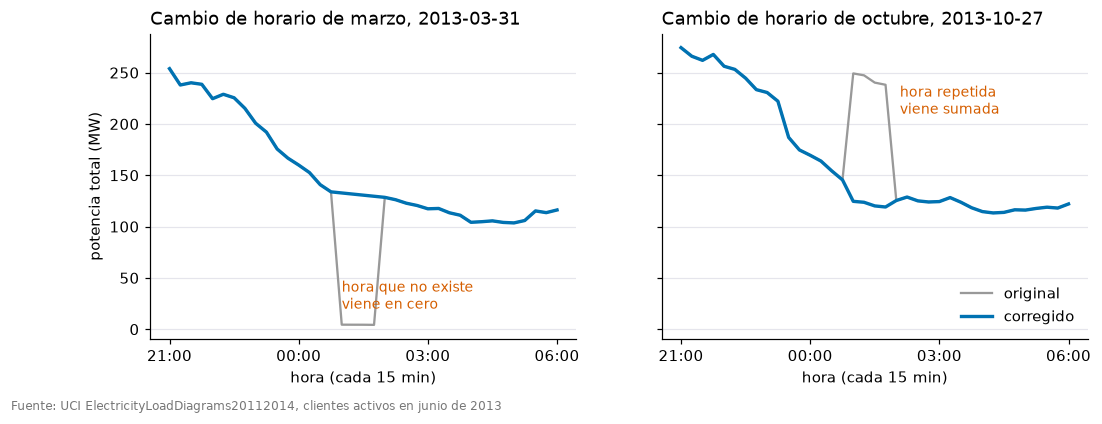

In [4]:
corregido = D.corregir_cambio_horario(crudo)
activos = (crudo.loc["2013-06"] > 0).mean() > 0.9
marzo, octubre = D.dias_cambio_horario([2013])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, dia, nombre in [(axes[0], marzo[0], "marzo"), (axes[1], octubre[0], "octubre")]:
    tramo = slice(dia - pd.Timedelta("3h"), dia + pd.Timedelta("6h"))
    ax.plot(crudo.loc[tramo, activos].sum(axis=1) / 1000, color=GRIS, lw=1.5, label="original")
    ax.plot(corregido.loc[tramo, activos].sum(axis=1) / 1000, color=AZUL, lw=2.2, label="corregido")
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    estilo(ax, f"Cambio de horario de {nombre}, {dia.date()}", xlabel="hora (cada 15 min)")
axes[0].set_ylabel("potencia total (MW)")
axes[0].text(marzo[0] + pd.Timedelta("1h"), 20, "hora que no existe\nviene en cero", color=NARANJA, fontsize=9)
axes[1].text(octubre[0] + pd.Timedelta("2h05min"), 210, "hora repetida\nviene sumada", color=NARANJA, fontsize=9)
axes[1].legend(frameon=False, loc="lower right")
pie(fig, "UCI ElectricityLoadDiagrams20112014, clientes activos en junio de 2013")
guardar(fig, "1_cambio_horario")
plt.show()

In [5]:
# Pipeline completo, corregir a 15 min, pasar a horas, filtrar clientes y guardar el panel
panel = D.construir_panel()
horario = D.cargar_horario_todos()
clientes = D.cargar_clientes()
cal = F.construir_calendario()
print("Horas en el archivo horario", horario.shape)

Horas en el archivo horario (35064, 370)


### 4. Clientes y observaciones del panel

¿Cuántos clientes quedan después del filtro del periodo 2012 a 2014? ¿Cuántas observaciones horarias tiene cada serie y cuántas tiene el panel completo?

El enunciado pide solo clientes con datos completos desde el 2012-01-01. Muchos clientes tienen ceros antes de empezar a medirse, y algunos se quedan en cero por meses o dejan de consumir antes del final. Un cliente se queda si cumple las cuatro condiciones de la tabla de abajo.

In [6]:
crit = D.criterios_filtro(horario)
pasos = pd.Series({
    "clientes en el archivo": len(crit),
    "consumen el 1 de enero de 2012": int(crit.activo_1_ene_2012.sum()),
    "y sin rachas de ceros de más de 7 días": int((crit.activo_1_ene_2012 & (crit.racha_ceros_h <= 168)).sum()),
    "y con menos de 10 % de horas en cero": int((crit.activo_1_ene_2012 & (crit.racha_ceros_h <= 168)
                                                 & (crit.frac_ceros < 0.10)).sum()),
    "y que siguen consumiendo al final de 2014": len(clientes["filtrados"]),
})
print(pasos.to_string())
quitados = crit[crit.activo_1_ene_2012 & ~crit.index.isin(clientes["filtrados"])]
print("\nClientes activos en 2012 que se quitaron por las otras condiciones")
quitados.round(3)

clientes en el archivo                       370
consumen el 1 de enero de 2012               320
y sin rachas de ceros de más de 7 días       317
y con menos de 10 % de horas en cero         314
y que siguen consumiendo al final de 2014    313

Clientes activos en 2012 que se quitaron por las otras condiciones


,activo_1_ene_2012,racha_ceros_h,frac_ceros,activo_final
MT_130,True,17,0.564,False
MT_131,True,1230,0.461,True
MT_132,True,118,0.512,True
MT_223,True,19914,0.757,False
MT_288,True,144,0.020,False
MT_347,True,10760,0.606,False
MT_348,True,27,0.469,True


In [7]:
n_filtrados = len(clientes["filtrados"])
horas_serie = len(pd.date_range(C.INICIO, C.FIN, freq="h"))
print(f"Horas por serie entre 2012-01-01 y 2014-12-31  {horas_serie:,}")
print(f"Panel completo ({n_filtrados} clientes)          {n_filtrados * horas_serie:,} observaciones")
print(f"Panel de trabajo ({panel.unique_id.nunique()} clientes)        {len(panel):,} observaciones")
assert (panel.groupby("unique_id").size() == horas_serie).all()
assert panel.y.isna().sum() == 0

Horas por serie entre 2012-01-01 y 2014-12-31  26,304
Panel completo (313 clientes)          8,233,152 observaciones
Panel de trabajo (100 clientes)        2,630,400 observaciones


Quedan 313 clientes de los 370. Cada serie tiene 26,304 horas (1,096 días por 24, porque 2012 es bisiesto), así que el panel completo tiene 8,233,152 observaciones.

El enunciado permite usar un subconjunto de al menos 100 clientes elegidos con semilla fija. Se usan 100 clientes elegidos con semilla 42 entre los 313, y son los mismos para todos los modelos de los dos integrantes. Ese panel de trabajo tiene 2,630,400 observaciones y está en `data/processed/panel_horario.parquet` con las columnas `unique_id`, `ds` y `y`.

### 5. Perfiles de consumo, feriados y fin de año

Los clientes tienen escalas muy distintas. Si se promedia el consumo en kWh, los perfiles solo reflejan a los clientes grandes. Por eso aquí cada cliente se divide entre su propio consumo promedio y luego se promedian todos. Un valor de 1.2 quiere decir 20 % más que lo normal de ese cliente.

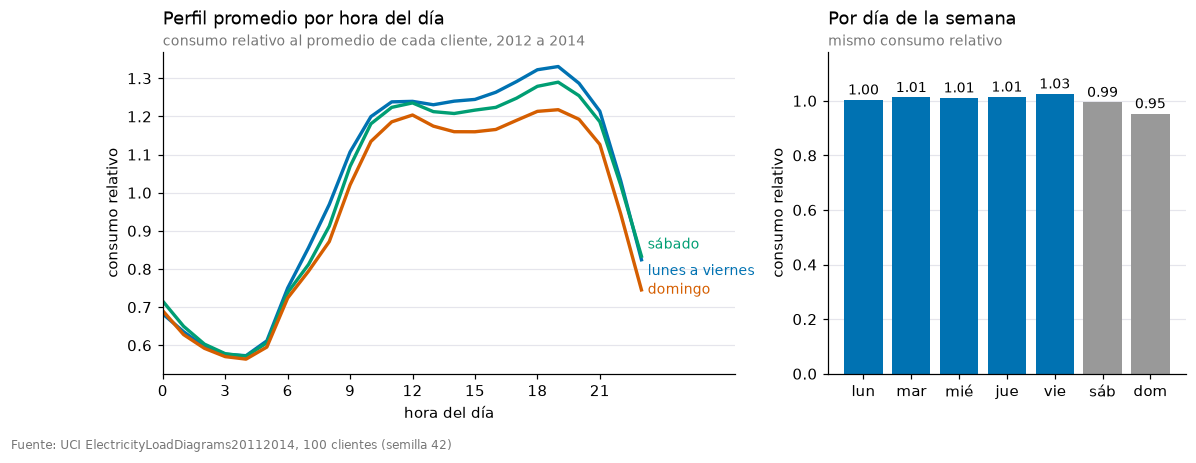

In [8]:
ancho = panel.pivot(index="ds", columns="unique_id", values="y")
relativo = ancho / ancho.loc[:C.FIN_TRAIN].mean()
prom = relativo.mean(axis=1)
dow = prom.index.day_of_week
tipo = np.where(dow < 5, "lunes a viernes", np.where(dow == 5, "sábado", "domingo"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
perfil = prom.groupby([tipo, prom.index.hour]).mean().unstack(0)
for col, color, dy in [("lunes a viernes", AZUL, -0.03), ("sábado", VERDE, 0.03), ("domingo", NARANJA, 0)]:
    ax.plot(perfil.index, perfil[col], color=color, lw=2.2)
    ax.text(23.3, perfil[col].iloc[-1] + dy, col, color=color, va="center", fontsize=9)
ax.set_xlim(0, 27.5)
ax.set_xticks(range(0, 24, 3))
estilo(ax, "Perfil promedio por hora del día", "consumo relativo al promedio de cada cliente, 2012 a 2014",
       "hora del día", "consumo relativo")

ax = axes[1]
nombres = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
por_dia = prom.groupby(dow).mean()
ax.bar(nombres, por_dia.values, color=[AZUL] * 5 + [GRIS] * 2)
for i, v in enumerate(por_dia.values):
    ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=9)
estilo(ax, "Por día de la semana", "mismo consumo relativo", None, "consumo relativo")
ax.set_ylim(0, por_dia.max() * 1.15)
pie(fig)
guardar(fig, "1_perfil_hora_dia")
plt.show()

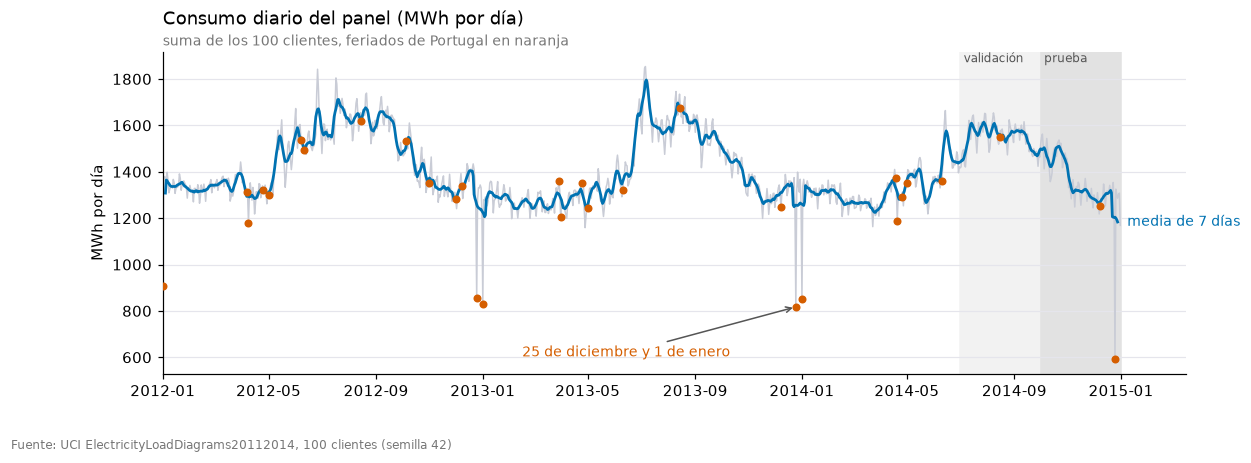

In [9]:
diario = ancho.resample("D").sum().sum(axis=1) / 1000
fer = F.feriados_portugal([2012, 2013, 2014])
dias_fer = pd.DatetimeIndex([pd.Timestamp(d) for d in fer if pd.Timestamp(d) in diario.index])

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(diario.index, diario.values, color=GRIS_CLARO, lw=1)
ax.plot(diario.rolling(7, center=True).mean(), color=AZUL, lw=1.8)
ax.scatter(dias_fer, diario.loc[dias_fer], color=NARANJA, s=18, zorder=3)
ax.text(diario.index[-1] + pd.Timedelta(days=8), diario.rolling(7, center=True).mean().dropna().iloc[-1],
        "media de 7 días", color=AZUL, fontsize=9, va="center")
ax.annotate("25 de diciembre y 1 de enero", xy=(pd.Timestamp("2013-12-25"), diario.loc["2013-12-25"]),
            xytext=(pd.Timestamp("2013-02-15"), diario.min() * 1.02), color=NARANJA, fontsize=9,
            arrowprops=dict(arrowstyle="->", color="#555555"))
for ini, fin, nombre, tono in [(C.INICIO_VAL, C.FIN_VAL, "validación", "#F2F2F2"), (C.INICIO_TEST, C.FIN_TEST, "prueba", "#E2E2E2")]:
    ax.axvspan(ini, fin, color=tono, zorder=0)
    ax.text(ini + pd.Timedelta(days=4), diario.max() * 1.01, nombre, color="#555555", fontsize=8)
ax.set_xlim(diario.index[0], diario.index[-1] + pd.Timedelta(days=75))
estilo(ax, "Consumo diario del panel (MWh por día)", "suma de los 100 clientes, feriados de Portugal en naranja",
       None, "MWh por día")
pie(fig)
guardar(fig, "1_serie_diaria_feriados")
plt.show()

In [10]:
# Consumo de cada día comparado con el mismo día de la semana en las 3 semanas anteriores
def caida(dia):
    dia = pd.Timestamp(dia)
    previos = [dia - pd.Timedelta(weeks=k) for k in (3, 4, 5)]
    return 100 * (diario.loc[dia] / diario.loc[previos].mean() - 1)

dias = ["12-24", "12-25", "12-26", "12-31", "01-01", "01-02"]
tabla = pd.DataFrame({
    "2012-13": [caida(f"{2012 if d[:2] == '12' else 2013}-{d}") for d in dias],
    "2013-14": [caida(f"{2013 if d[:2] == '12' else 2014}-{d}") for d in dias],
    "2014": [caida(f"2014-{d}") if d[:2] == "12" else np.nan for d in dias],
}, index=["24 dic", "25 dic", "26 dic", "31 dic", "1 ene", "2 ene"])
print("Cambio en % contra el mismo día de la semana 3 a 5 semanas antes")
tabla.round(1)

Cambio en % contra el mismo día de la semana 3 a 5 semanas antes


,2012-13,2013-14,2014
24 dic,-4.8,-3.5,-4.3
25 dic,-34.6,-36.0,-54.3
26 dic,-1.8,1.2,-0.8
31 dic,-6.1,-3.5,-8.7
1 ene,-36.7,-34.2,NaN
2 ene,-2.4,2.0,NaN


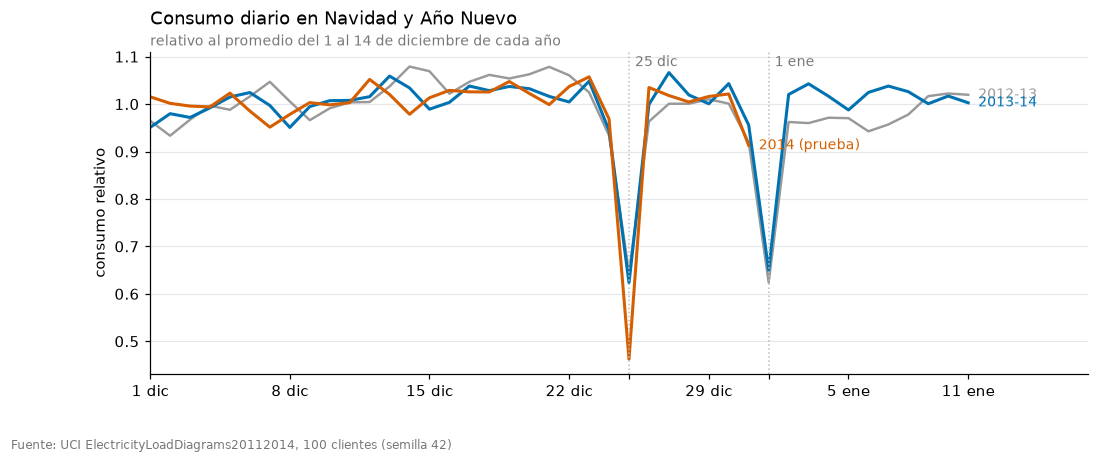

In [11]:
fig, ax = plt.subplots(figsize=(11, 3.8))
for ini, color, nombre in [("2012-12-01", GRIS, "2012-13"), ("2013-12-01", AZUL, "2013-14"), ("2014-12-01", NARANJA, "2014 (prueba)")]:
    ini = pd.Timestamp(ini)
    tramo = diario.loc[ini:ini + pd.Timedelta(days=41)]
    x = (tramo.index - ini).days
    rel = tramo / diario.loc[ini:ini + pd.Timedelta(days=13)].mean()
    ax.plot(x, rel.values, color=color, lw=2 if color != GRIS else 1.6)
    ax.text(x[-1] + 0.5, rel.values[-1], nombre, color=color, fontsize=9, va="center")
for d, txt in [(24, "25 dic"), (31, "1 ene")]:
    ax.axvline(d, color="#BBBBBB", ls=":", lw=1)
    ax.text(d + 0.3, 1.08, txt, color="#777777", fontsize=9)
ax.set_xticks([0, 7, 14, 21, 24, 28, 31, 35, 41])
ax.set_xticklabels(["1 dic", "8 dic", "15 dic", "22 dic", "", "29 dic", "", "5 ene", "11 ene"])
ax.set_xlim(0, 47)
estilo(ax, "Consumo diario en Navidad y Año Nuevo", "relativo al promedio del 1 al 14 de diciembre de cada año",
       None, "consumo relativo")
pie(fig)
guardar(fig, "1_navidad")
plt.show()

El ciclo más fuerte es el diario. El consumo llega a su mínimo entre las 3 y las 4 de la mañana, sube rápido desde las 6, se mantiene alto durante el día y tiene su máximo cerca de las 19 horas. Entre días de la semana la diferencia es menor. De lunes a sábado el consumo es casi igual y el domingo baja cerca de 5 %, sobre todo en la tarde.

También hay un ciclo anual. El consumo es más alto en julio y agosto que en el resto del año. Eso importa porque validación (julio a septiembre) cae en la temporada alta y prueba (octubre a diciembre) en una época donde el nivel va bajando, así que hay un cambio de nivel entre los dos bloques.

No todos los feriados bajan el consumo. Varios, como el 15 de agosto o el 10 de junio, quedan casi en la media de su semana. Los que sí bajan mucho son el 25 de diciembre y el 1 de enero, que son los días más bajos de cada año. Contra el mismo día de la semana de 3 a 5 semanas antes, el 25 de diciembre cae entre 35 % y 36 % en 2012 y 2013 y 54 % en 2014, y el 1 de enero cae entre 34 % y 37 %. El 24 y el 31 de diciembre bajan poco (entre 3 % y 9 %) y el 26 de diciembre y el 2 de enero ya son días normales. La semana del 22 al 28 de diciembre de 2014 está en prueba. Un modelo que solo copie el día anterior va a fallar el 25 y también el 26, porque ese día copia la caída de Navidad.

### 6. Escalas entre clientes y normalización

¿Qué tan distintas son las escalas entre clientes? Se mide con el consumo promedio por hora de cada cliente en el bloque de entrenamiento.

In [12]:
todos = horario.loc[C.INICIO:C.FIN_TRAIN, clientes["filtrados"]].mean()
elegidos = ancho.loc[:C.FIN_TRAIN].mean()
escalas = pd.DataFrame({"313 clientes filtrados": todos.describe(), "100 clientes del panel": elegidos.describe()}).T
escalas = escalas[["min", "25%", "50%", "75%", "max"]].rename(columns={"50%": "mediana"})
print("Consumo promedio por hora en entrenamiento (kWh)")
print(escalas.round(2).to_string())
print(f"\nEl cliente más grande consume {elegidos.max() / elegidos.min():,.0f} veces más que el más chico")

Consumo promedio por hora en entrenamiento (kWh)
                          min    25%  mediana     75%       max
313 clientes filtrados   4.33  75.10   148.48  378.34  48818.15
100 clientes del panel  20.87  81.26   172.96  458.37  11479.72

El cliente más grande consume 550 veces más que el más chico


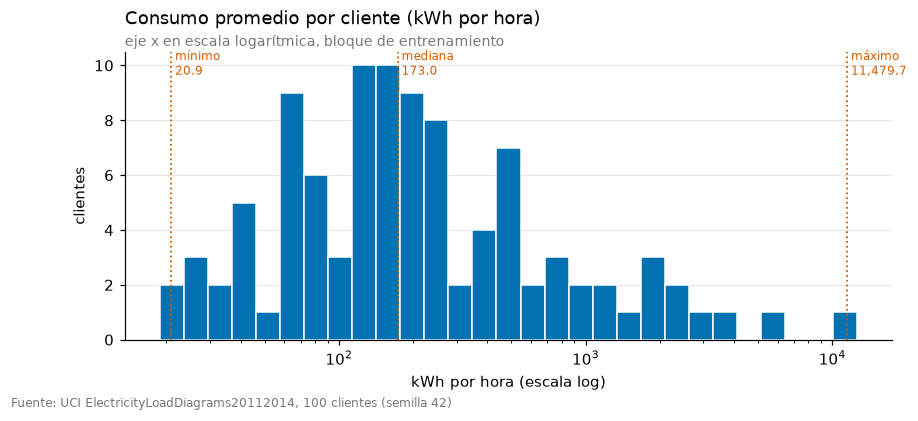

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.4))
bins = np.logspace(np.log10(elegidos.min() * 0.9), np.log10(elegidos.max() * 1.1), 30)
ax.hist(elegidos, bins=bins, color=AZUL, edgecolor="white")
ax.set_xscale("log")
for q, nombre in [(elegidos.min(), "mínimo"), (elegidos.median(), "mediana"), (elegidos.max(), "máximo")]:
    ax.axvline(q, color=NARANJA, ls=":", lw=1.2)
    ax.text(q, ax.get_ylim()[1] * 0.92, f" {nombre}\n {q:,.1f}", color=NARANJA, fontsize=8)
estilo(ax, "Consumo promedio por cliente (kWh por hora)", "eje x en escala logarítmica, bloque de entrenamiento",
       "kWh por hora (escala log)", "clientes")
pie(fig)
guardar(fig, "1_escalas_clientes")
plt.show()

Las escalas son muy distintas. En los 313 clientes filtrados el promedio va de 4.3 a 48,818 kWh por hora, con mediana de 148. En los 100 del panel va de 20.9 a 11,480 kWh por hora, con mediana de 173, o sea que el cliente más grande consume unas 550 veces más que el más chico. Con una normalización global, la pérdida quedaría dominada por los pocos clientes grandes y los chicos casi no aportarían al entrenamiento. Con una normalización por ventana se pierde la información del nivel de cada cliente y el modelo depende solo de las últimas L horas.

Se eligió z-score por serie, o sea restar la media y dividir entre la desviación de cada cliente, calculadas solo con el bloque de entrenamiento (2012-01-01 a 2014-06-30). Así todas las series quedan en una escala parecida, cada cliente pesa lo mismo en la pérdida y no se usa nada del futuro. La normalización global y RevIN (una versión por ventana que se puede deshacer) se prueban como iteraciones en el notebook 3. Las métricas siempre se calculan después de deshacer la normalización, en kWh.

### 7. Covariables de calendario

Las covariables son hora del día, día de la semana, mes y feriado. Todas se conocen de antemano para cualquier hora futura, así que se pueden usar en las horas a pronosticar sin fuga.

- Hora, día de la semana y mes van con seno y coseno. Con un número del 0 al 23 la red vería la hora 23 muy lejos de la 0, cuando en realidad son vecinas. El par seno y coseno pone cada valor en un círculo y deja juntas a las horas cercanas. Además agrega solo 6 columnas, contra 24 + 7 + 12 de un one-hot.
- Feriado va como 0 o 1 según el paquete `holidays` para Portugal. El paquete ya toma en cuenta que Portugal suspendió 4 feriados entre 2013 y 2015 (Corpo de Deus, 5 de octubre, 1 de noviembre y 1 de diciembre).

No se usaron embeddings porque con tan pocas categorías el seno y coseno funciona bien y sirve igual para todos los modelos, incluidos los de librería.

In [14]:
print("Feriados de 2014")
print(pd.Series({d: n for d, n in sorted(F.feriados_portugal([2014]).items())}).to_string())
cal.set_index("ds").iloc[[0, 1, 12, 23, 24]].round(3)

Feriados de 2014
2014-01-01                                             Ano Novo
2014-04-18                                    Sexta-feira Santa
2014-04-20                                               Páscoa
2014-04-25                                     Dia da Liberdade
2014-05-01                                   Dia do Trabalhador
2014-06-10    Dia de Portugal, de Camões e das Comunidades P...
2014-08-15                            Assunção de Nossa Senhora
2014-12-08                                  Imaculada Conceição
2014-12-25                                         Dia de Natal


,hora_sin,hora_cos,dow_sin,dow_cos,mes_sin,mes_cos,feriado
ds,,,,,,,
2012-01-01 00:00:00,0.000,1.000,-0.782,0.623,0.0,1.0,1.0
2012-01-01 01:00:00,0.259,0.966,-0.782,0.623,0.0,1.0,1.0
2012-01-01 12:00:00,0.000,-1.000,-0.782,0.623,0.0,1.0,1.0
2012-01-01 23:00:00,-0.259,0.966,-0.782,0.623,0.0,1.0,1.0
2012-01-02 00:00:00,0.000,1.000,0.000,1.000,0.0,1.0,0.0


### 8. Dataset de ventanas para PyTorch

`VentanasDataset` (en `src/dataset.py`) arma ventanas deslizantes de todas las series. Una ventana se define por su cliente y por t0, la primera hora del objetivo.

- La entrada X va de t0 − L a t0 − 1 y tiene 8 columnas, la serie normalizada y las 7 covariables de calendario.
- El objetivo y va de t0 a t0 + H − 1.
- Con `futuro=True` también entrega el calendario de las horas del objetivo, que usan el MLP, la LSTM y el decoder del seq2seq.

Una ventana pertenece al bloque donde cae todo su objetivo. La entrada sí puede venir del bloque anterior, porque es pasado y ya se conoce cuando se emite el pronóstico. Además de `__getitem__`, la clase tiene un método `lote` que arma un lote completo con indexación avanzada directo en la GPU, lo que evita el costo de un DataLoader en MPS.

In [15]:
Y, ids, ds = panel_a_matriz(panel)
esc = Escalador("serie").ajustar(Y, 0, indice(ds, C.FIN_TRAIN))
Yn = esc.transformar(Y)
cal_np = cal.set_index("ds").loc[ds, C.COLUMNAS_CALENDARIO].to_numpy()

t0_train = t0_bloque(ds, C.INICIO, C.FIN_TRAIN)
dset = VentanasDataset(Yn, cal_np, t0_train, C.L, C.H)
X, y = next(iter(DataLoader(dset, batch_size=32, shuffle=True)))
print("X", tuple(X.shape), "  (batch, L, features)")
print("y", tuple(y.shape), "  (batch, H)")

dset_f = VentanasDataset(Yn, cal_np, t0_train, C.L, C.H, futuro=True)
X, Xf, y = next(iter(DataLoader(dset_f, batch_size=32)))
print("Con futuro=True también sale Xf", tuple(Xf.shape), "  (batch, H, covariables)")

X (32, 168, 8)   (batch, L, features)
y (32, 24)   (batch, H)
Con futuro=True también sale Xf (32, 24, 7)   (batch, H, covariables)


In [16]:
conteo = contar_ventanas(ds, len(ids), C.L, C.H, stride=1)
conteo

,bloque,ventanas_por_serie,ventanas_panel,primer_objetivo,ultimo_objetivo
0,entrenamiento,21697,2169700,2012-01-08,2014-06-30 23:00:00
1,validación,2185,218500,2014-07-01,2014-09-30 23:00:00
2,prueba,2185,218500,2014-10-01,2014-12-31 23:00:00


Con L = 168, H = 24 y stride de 1 hora, el panel de 100 clientes produce 2,169,700 ventanas de entrenamiento, 218,500 de validación y 218,500 de prueba. Por cliente son 21,697, 2,185 y 2,185. En entrenamiento se restan las primeras 168 horas porque no tienen pasado suficiente para la entrada.

En la evaluación no se usan todas esas ventanas de prueba. El protocolo de la sección 4 usa un origen por día a las 00:00, así que son 92 orígenes por cliente en prueba (y también 92 en validación).

### 9. Auditoría de fugas

Cada entrada de la red debe poder calcularse en el instante en que se emite el pronóstico. Para cada una de las cuatro fugas vistas en clase se muestra con código cómo la evita el pipeline.

#### Fuga 1. Split aleatorio de ventanas

Si las ventanas se reparten al azar entre entrenamiento, validación y prueba, el modelo entrena con horas que están justo al lado de las de prueba. Aquí los bloques se cortan por fecha y cada ventana va al bloque donde cae todo su objetivo. Dentro de entrenamiento sí se muestrean ventanas al azar en cada epoch, pero solo entre las de entrenamiento.

In [17]:
bloques = {"entrenamiento": t0_bloque(ds, C.INICIO, C.FIN_TRAIN),
           "validación": t0_bloque(ds, C.INICIO_VAL, C.FIN_VAL),
           "prueba": t0_bloque(ds, C.INICIO_TEST, C.FIN_TEST)}
for nombre, t0s in bloques.items():
    print(f"{nombre:14s} objetivos de {ds[t0s.min()]} a {ds[t0s.max() + C.H - 1]}")

fin_obj_train = ds[bloques["entrenamiento"].max() + C.H - 1]
assert fin_obj_train < ds[bloques["validación"].min()] <= ds[bloques["validación"].max() + C.H - 1] < ds[bloques["prueba"].min()]
assert not set(bloques["entrenamiento"]) & set(bloques["validación"])
assert not set(bloques["validación"]) & set(bloques["prueba"])
print("\nNingún objetivo de entrenamiento cae en validación o prueba, y ninguno de validación cae en prueba")

entrenamiento  objetivos de 2012-01-08 00:00:00 a 2014-06-30 23:00:00
validación     objetivos de 2014-07-01 00:00:00 a 2014-09-30 23:00:00
prueba         objetivos de 2014-10-01 00:00:00 a 2014-12-31 23:00:00

Ningún objetivo de entrenamiento cae en validación o prueba, y ninguno de validación cae en prueba


#### Fuga 2. Escalar con toda la serie

Si la media y la desviación se calculan con toda la serie, el modelo recibe información del nivel de consumo de prueba. Aquí `Escalador.ajustar` recibe el índice de la última hora de entrenamiento y solo mira esas columnas.

In [18]:
print("El escalador se ajustó con las horas", ds[esc.rango[0]], "a", ds[esc.rango[1]])
assert ds[esc.rango[1]] == C.FIN_TRAIN

media_toda = Y.mean(axis=1)
cambio = 100 * (media_toda / esc.media[:, 0] - 1)
print(f"Si se usara toda la serie, la media cambiaría en promedio {np.abs(cambio).mean():.1f} % por cliente")
print(f"y hasta {np.abs(cambio).max():.1f} % en el cliente con más cambio ({ids[np.abs(cambio).argmax()]})")

El escalador se ajustó con las horas 2012-01-01 00:00:00 a 2014-06-30 23:00:00
Si se usara toda la serie, la media cambiaría en promedio 0.9 % por cliente
y hasta 6.9 % en el cliente con más cambio (MT_157)


#### Fuga 3. Early stopping con la prueba

Si se detiene el entrenamiento cuando mejora el error de prueba, la prueba deja de ser una medición limpia. En `src/entrenamiento.py` el early stopping y la selección de configuraciones usan solo ventanas con objetivo en validación (92 orígenes diarios por cliente). La prueba solo se usa una vez por modelo, en `evaluar_final`, con la configuración que ganó en validación.

In [19]:
t0_val = t0_bloque(ds, C.INICIO_VAL, C.FIN_VAL, solo_00=True)
print(f"Ventanas de early stopping por cliente {len(t0_val)}, objetivos de {ds[t0_val.min()]} a {ds[t0_val.max() + C.H - 1]}")
assert ds[t0_val.max() + C.H - 1] <= C.FIN_VAL < C.INICIO_TEST

import inspect
from src import entrenamiento
fuente = inspect.getsource(entrenamiento.entrenar)
assert "INICIO_TEST" not in fuente and "FIN_TEST" not in fuente
print("La función entrenar no menciona ninguna fecha de prueba")
print([l.strip() for l in fuente.splitlines() if "t0_val =" in l][0])

Ventanas de early stopping por cliente 92, objetivos de 2014-07-01 00:00:00 a 2014-09-30 23:00:00
La función entrenar no menciona ninguna fecha de prueba
t0_val = t0_bloque(datos.ds, C.INICIO_VAL, C.FIN_VAL, L, H, solo_00=True)


#### Fuga 4. Covariables mal alineadas

Una covariable mal alineada puede meter el valor real del día a pronosticar, por ejemplo usar el consumo de las 00:00 como entrada del pronóstico de las 00:00. Aquí la entrada solo tiene la serie hasta las 23:00 del día anterior y el calendario, que se conoce para cualquier fecha futura. El decoder recibe solo el calendario de las horas a pronosticar.

Además `backtest` (sección 4, notebook 3) revisa en cada origen que la historia que recibe el modelo termine antes del origen y que los pronósticos empiecen justo en el origen.

In [20]:
dset_val = VentanasDataset(Yn, cal_np, t0_val, C.L, C.H, futuro=True)
X, Xf, y, s = dset_val.lote(torch.arange(len(dset_val)))
t0 = dset_val.t0.numpy()
fin_entrada = ds[t0 - 1]
inicio_obj = ds[t0]
assert (fin_entrada.hour == 23).all() and (inicio_obj.hour == 0).all()

# La columna 0 de X tiene solo valores anteriores al origen y y tiene los del día pronosticado
k = 1234
assert np.allclose(X[k, :, 0].numpy(), Yn[int(s[k]), t0[k] - C.L:t0[k]], atol=1e-6)
assert np.allclose(y[k].numpy(), Yn[int(s[k]), t0[k]:t0[k] + C.H], atol=1e-6)

# El calendario de entrada y el del objetivo corresponden a sus propias horas
assert np.allclose(X[k, :, 1:].numpy(), cal_np[t0[k] - C.L:t0[k]], atol=1e-6)
assert np.allclose(Xf[k].numpy(), cal_np[t0[k]:t0[k] + C.H], atol=1e-6)
print("Última hora de entrada", fin_entrada[k], "  primera hora del objetivo", inicio_obj[k])
print("Las covariables de X y Xf coinciden con sus horas y ninguna entrada trae y del día pronosticado")

Última hora de entrada 2014-08-07 23:00:00   primera hora del objetivo 2014-08-08 00:00:00
Las covariables de X y Xf coinciden con sus horas y ninguna entrada trae y del día pronosticado


### Resumen de las decisiones

| Decisión | Valor |
| --- | --- |
| Clientes | 313 pasan el filtro, se usan 100 con semilla 42 |
| Horas por serie | 26,304 |
| Cambio de horario | Interpolar en marzo, dividir entre 2 en octubre (marcas 01:00 a 01:45) |
| Normalización | z-score por serie con estadísticos de entrenamiento |
| Covariables | hora, día y mes con seno y coseno, feriado 0/1 |
| Ventanas con L = 168 y H = 24 | 2,169,700 de entrenamiento, 218,500 de validación y 218,500 de prueba |